[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C3_NB05_mpr_mean_field.ipynb)

# Day 1 · Chapter 3 · Notebook 05 — A crowd of neurons described by two numbers (Montbrió–Pazó–Roxin)

**Goal.** In NB03 we simulated 10 000 QIF neurons and saw a low-activity state, a high-activity state,
collective oscillations, memory and bursting. Following 10 000 neurons is expensive and hard to understand. Can we
describe the **whole crowd** with a few numbers instead?

Think of a stadium: you do not need to know what each person does to say "the crowd is quiet", "the crowd is
cheering", or "the crowd is doing a wave". For QIF neurons, Montbrió, Pazó & Roxin (2015, "MPR") showed that **two
numbers** are enough, and that they follow two simple equations, the **mean field**:

* the **firing rate** $r$: how many neurons fire per unit time (how loud the crowd is);
* the **typical voltage** $v$: how close the typical neuron is to firing (how excited the crowd is).

In this notebook we
1. see *why* two numbers are enough;
2. check that the two-number model reproduces the 10 000-neuron network (**Fig. 2 of MPR**);
3. use it to understand the behaviours of the population: low and high activity, **memory**, and the **map of
   regimes** (MPR Fig. 1).

We use the mean field as a ready-made tool (`meanfield.mpr`); you do not need its equations to follow the notebook.

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
import time
from src import networks, meanfield

<details><summary><b>For the curious: the two equations</b> (click to open; not needed for the rest)</summary>

Network (NB03): each neuron $j$ follows $\;dv_j/dt = v_j^2 + \eta_j + J\,r(t) + I(t)$.
Mean field (MPR 2015), for a very large network:

$$
\frac{dr}{dt} = \frac{\Delta}{\pi} + 2\,r\,v, \qquad
\frac{dv}{dt} = v^2 + \bar\eta + J\,r + I(t) - \pi^2 r^2
$$

$\bar\eta$ is the average excitability, $\Delta$ how different the neurons are from each other, $J$ the coupling,
$I$ the input. The second equation looks like a single QIF neuron (NB02) with extra terms for the population.
</details>

## 1. Why two numbers are enough

We run the network of NB03 (10 000 neurons, an input step $I=3$ from $t=0$ to $t=30$) and take snapshots of the
voltages of **all** neurons (blue histograms). On top (orange) we draw the shape that the two-number model predicts:
a bell-shaped curve whose **position** is the typical voltage $v$ and whose **width** grows with the rate $r$.

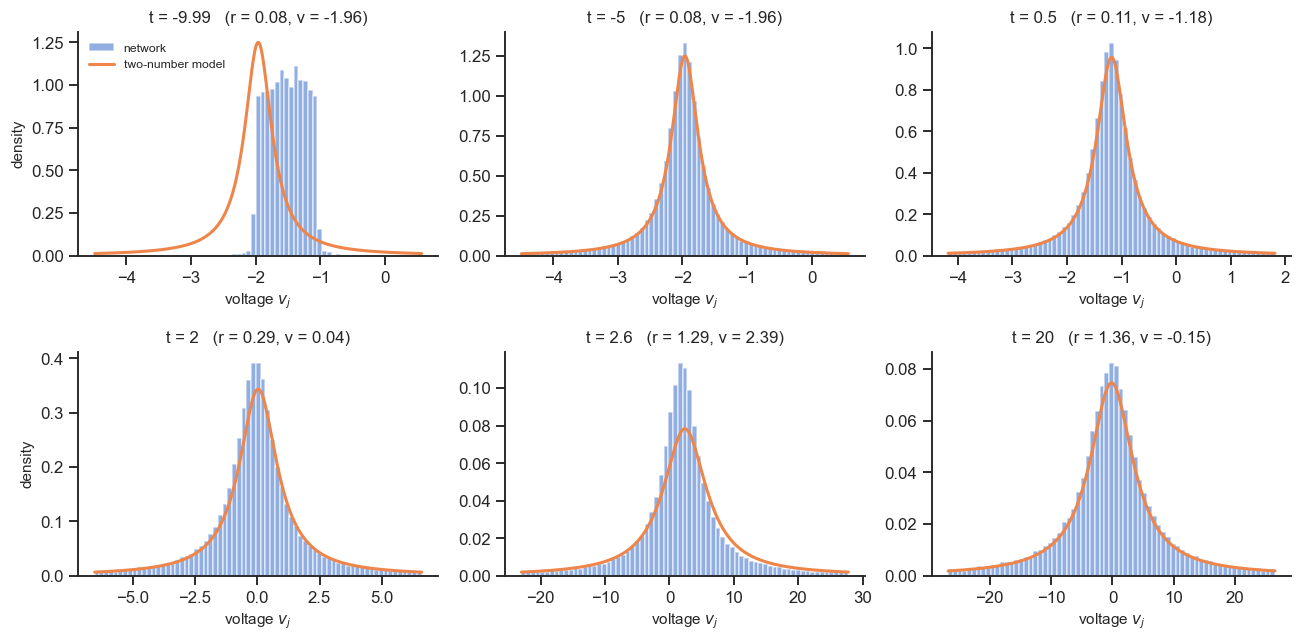

In [2]:
dt = 1e-4
T0, T = -10.0, 70.0
t = np.arange(T0, T, dt)
I_step = np.where((t >= 0) & (t < 30), 3.0, 0.0)
I_sin = 3.0 * np.sin(np.pi * t / 20.0) * (t >= 0)

r_low, v_low = meanfield.mpr_fixed_points(eta_bar=-5.0, J=15.0)[0]      # low-activity state
t_snap = np.array([-9.99, -5.0, 0.5, 2.0, 2.6, 20.0])
tb, r_net, v_net, st, si, snaps = networks.qif_network(I_step, N=10000, dt=dt, bin_size=0.02,
                                                      snap_times=t_snap - T0, seed=0)
r_mf, v_mf = meanfield.mpr(I_step, dt=dt, r0=r_low, v0=v_low)

fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a_, ts, x in zip(ax.flat, t_snap, snaps):
    x = x[~np.isnan(x)]
    i = int(round((ts - T0) / dt))
    w = np.pi * r_mf[i]
    lo, hi = v_mf[i] - 6 * w - 1.0, v_mf[i] + 6 * w + 1.0
    a_.hist(x, bins=np.linspace(lo, hi, 70), density=True, color="C0", alpha=0.6, label="network")
    vv = np.linspace(lo, hi, 500)
    a_.plot(vv, meanfield.lorentzian_v_density(vv, v_mf[i], r_mf[i]), "C1", lw=2, label="two-number model")
    a_.set(title=f"t = {ts:g}   (r = {r_mf[i]:.2f}, v = {v_mf[i]:.2f})", xlabel="voltage $v_j$")
ax[0, 0].legend(fontsize=8); ax[0, 0].set_ylabel("density"); ax[1, 0].set_ylabel("density")
plt.tight_layout()

* $t=-9.99$: the network starts from voltages spread evenly between $-2$ and $-1$, **not** the predicted shape.
* $t=-5$: a few time units later the crowd has *forgotten* how it started and its voltages have taken the
  predicted shape. Whatever the starting point, the network falls into this shape and stays in it. So two numbers,
  position and width, describe it at all times.
* $t=0.5$ to $2.6$: when the input arrives, the crowd moves to the right (closer to firing) and widens (more
  neurons firing), and it keeps the same shape.
* $t=20$: the high-activity state, a wide distribution centred near 0.

## 2. 10 000 neurons vs 2 numbers (MPR Fig. 2)

Same network, two inputs: a step (left) and a slow sine wave (right). Top: raster of 300 neurons. Black: the
network. Orange: the two-number model.

time for one run:  network 4.53 s,  mean field 0.009 s


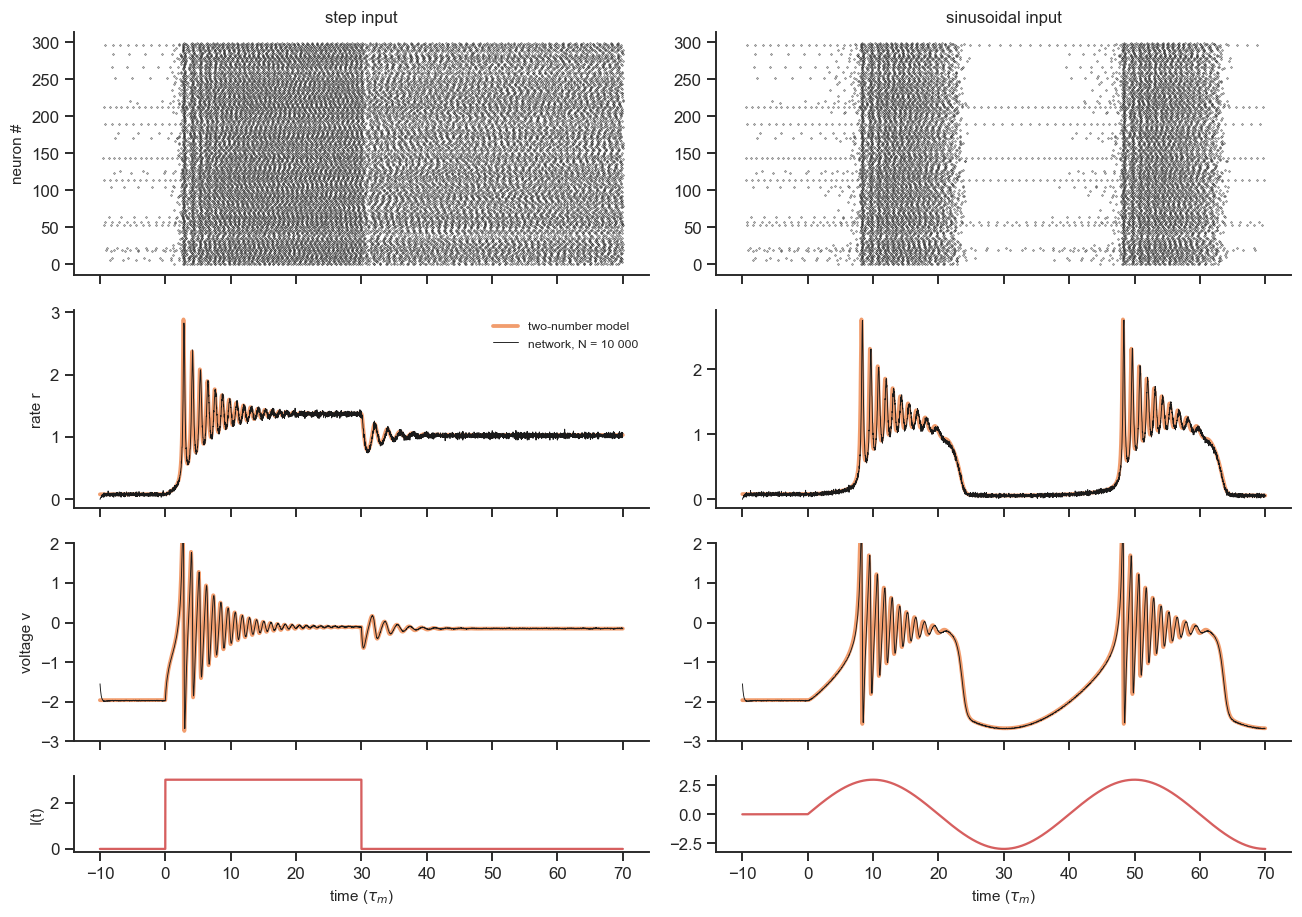

In [3]:
fig, ax = plt.subplots(4, 2, figsize=(12, 8.5), sharex=True, gridspec_kw=dict(height_ratios=[1.6, 1.3, 1.3, 0.5]))
timing = {}
for c, (name, I_ext) in enumerate([("step", I_step), ("sine", I_sin)]):
    t0 = time.perf_counter()
    tb, r_net, v_net, st, si = networks.qif_network(I_ext, N=10000, dt=dt, bin_size=0.02, n_rec=300, seed=0)
    timing["network"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    r_mf, v_mf = meanfield.mpr(I_ext, dt=dt, r0=r_low, v0=v_low)
    timing["mean field"] = time.perf_counter() - t0
    ax[0, c].plot(st + T0, si, ".k", ms=0.6)
    ax[1, c].plot(t, r_mf, "C1", lw=2.5, alpha=0.8, label="two-number model")
    ax[1, c].plot(tb + T0, r_net, "k", lw=0.6, label="network, N = 10 000")
    ax[2, c].plot(t, v_mf, "C1", lw=2.5, alpha=0.8)
    ax[2, c].plot(tb + T0, v_net, "k", lw=0.6)
    ax[3, c].plot(t, I_ext, "C3")
ax[0, 0].set(ylabel="neuron #", title="step input"); ax[0, 1].set(title="sinusoidal input")
ax[1, 0].set_ylabel("rate r"); ax[1, 0].legend(fontsize=8, loc="upper right")
ax[2, 0].set_ylabel("voltage v"); ax[2, 0].set_ylim(-3, 2); ax[2, 1].set_ylim(-3, 2)
ax[3, 0].set_ylabel("I(t)")
for a_ in ax[3]: a_.set_xlabel("time ($\\tau_m$)")
plt.tight_layout()
print(f"time for one run:  network {timing['network']:.2f} s,  mean field {timing['mean field']:.3f} s")

The two-number model reproduces everything we saw in the network: the switch to high activity, the **damped
collective oscillations** (the ringing right after the step), the **memory** (the network stays active after the
step is removed) and the **bursts** under the sine input. It only misses the small random fluctuations of the
finite network.

It runs thousands of times faster, but the main gain is understanding: with two numbers we can draw the state of
the whole population on a sheet of paper. This is what the rest of the notebook does.

> **Why not a classic rate model?** Older rate models (Wilson–Cowan, 1972) describe a population with the rate
> alone. They capture the memory but **not** the fast collective oscillations after the step: those come from the
> interplay of rate *and* voltage, which the MPR model keeps.

## 3. A map of the population: where does it go?

Because the population is described by two numbers, its state is **a point on a plane**: rate $r$ horizontally,
typical voltage $v$ vertically. As time goes on, the point moves. The grey arrows show where it moves from every
place on the plane (with no input, $I=0$). The coloured lines are trajectories started from different points:
red ones end in the high-activity state, purple ones in the low-activity state. (The blue and green curves mark
where the rate or the voltage stop changing; the states sit where they cross.)

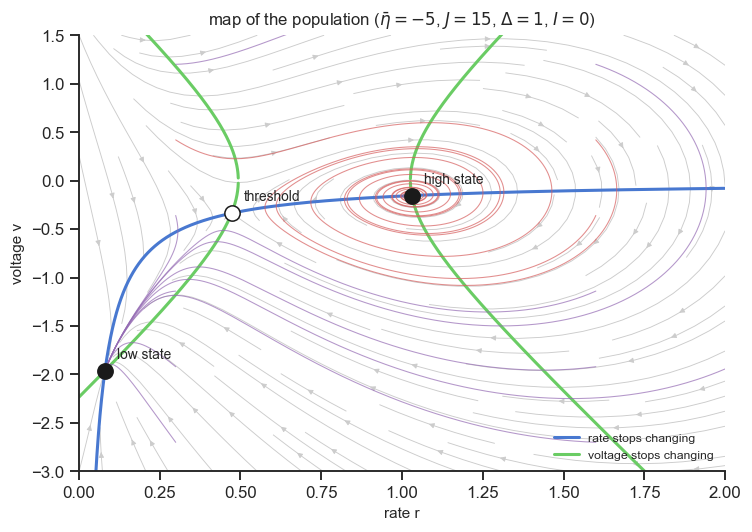

In [4]:
def nullclines(I, eta_bar=-5.0, J=15.0, delta=1.0, r=np.linspace(1e-3, 2.5, 3000)):
    vr = -delta / (2 * np.pi * r)
    arg = np.pi**2 * r**2 - J * r - eta_bar - I
    vp = np.where(arg >= 0, np.sqrt(np.clip(arg, 0, None)), np.nan)
    return r, vr, vp, -vp

def classify(r, v, J):
    lam = np.linalg.eigvals(meanfield.mpr_jacobian(r, v, J))
    stable = np.all(lam.real < 0)
    kind = ("stable " if stable else "unstable ") + ("focus" if np.any(lam.imag != 0) else ("node" if stable or np.all(lam.real > 0) else "saddle"))
    return lam, stable, kind

def phase_plane(ax, I, eta_bar=-5.0, J=15.0, delta=1.0, n_traj=True, vlim=(-3, 1.5), rmax=2.0):
    r, vr, vp, vm = nullclines(I, eta_bar, J, delta, np.linspace(1e-3, rmax, 3000))
    R, V = np.meshgrid(np.linspace(1e-3, rmax, 30), np.linspace(*vlim, 30))
    dR = delta / np.pi + 2 * R * V
    dV = V**2 + eta_bar + J * R + I - np.pi**2 * R**2
    ax.streamplot(R, V, dR, dV, color="0.8", density=1.0, linewidth=0.6, arrowsize=0.7)
    ax.plot(r, vr, "C0", lw=2, label="rate stops changing")
    ax.plot(r, vp, "C2", lw=2, label="voltage stops changing"); ax.plot(r, vm, "C2", lw=2)
    if n_traj:   # trajectories from a few initial conditions, coloured by where they end up
        for r0 in (0.3, 1.6):
            for v0 in np.linspace(vlim[0] + 0.3, vlim[1] - 0.3, 6):
                rr, vv = meanfield.mpr(np.full(20000, I), dt=1e-3, r0=r0, v0=v0, delta=delta, eta_bar=eta_bar, J=J)
                ax.plot(rr, vv, color="C3" if rr[-1] > 0.5 else "C4", lw=0.7, alpha=0.7)
    for rs, vs in meanfield.mpr_fixed_points(eta_bar, J, delta, I):
        lam, stable, kind = classify(rs, vs, J)
        ax.plot(rs, vs, "o", ms=10, mfc="k" if stable else "w", mec="k", zorder=5)
        label = {"stable node": "low state", "saddle": "threshold", "unstable saddle": "threshold", "stable focus": "high state"}.get(kind, kind)
        ax.annotate(label, (rs, vs), textcoords="offset points", xytext=(8, 8), fontsize=9)
    ax.set(xlim=(0, rmax), ylim=vlim, xlabel="rate r", ylabel="voltage v")

fig, ax = plt.subplots(figsize=(7, 5))
phase_plane(ax, I=0.0)
ax.set_title(r"map of the population ($\bar\eta=-5$, $J=15$, $\Delta=1$, $I=0$)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

Three special points (black = stable, white = unstable):

* **low state**: few neurons fire. Purple trajectories end here.
* **high state**: many neurons fire. Red trajectories **spiral** into it: the spiral is the damped collective
  oscillation of the network after the step.
* **threshold** (white): an unstable point between the two, like the top of a hill between two valleys. Starting
  on one side you roll into the low valley, on the other side into the high valley. It plays for the population the
  role that the firing threshold plays for a single neuron (NB02).

Two stable states with the same input means the population can be in either, depending on its history: this is
**bistability**, and it is the reason for the memory after the step.

### Explore: change the input and watch the map

Left: the map of section 3. Right: the **stable states as a function of the input** $I$ (black = stable states,
red = threshold), with the current $I$ marked.

* Increase $I$ slowly from 0. At which value do the low state and the threshold **meet and disappear**? After that,
  the population has no choice: it must go to the high state. This tipping point is called a **saddle-node
  bifurcation** (Chapter 4), the same tipping point as the single QIF neuron in NB02, one level up.
* Decrease $I$ below 0. Which state disappears now, and where?
* Set $J=5$ (weak coupling). Is the population still bistable for some $I$?
* Increase $\Delta$ (more different neurons). What happens to the bistable range?

In [5]:
def bif_diagram(ax, eta_bar, J, delta, I_range=(-4, 6), n=600):
    br = meanfield.mpr_branches(np.linspace(*I_range, n), eta_bar, J, delta)
    for stable, c in [(True, "k"), (False, "C3")]:
        b = np.array([(x[0], x[1]) for x in br if x[3] == stable] or [(np.nan, np.nan)])
        ax.plot(b[:, 0], b[:, 1], ".", c=c, ms=2, label="stable state" if stable else "threshold (unstable)")
    ax.set(xlabel="input I", ylabel="rate of the state", xlim=I_range, ylim=(0, 2))

@interact(I=slider(0.0, -3.0, 5.0, 0.1, "input I"),
          J=slider(15.0, 0.0, 25.0, 0.5, "coupling J"),
          eta_bar=slider(-5.0, -10.0, 2.0, 0.25, "mean excitability eta_bar"),
          delta=slider(1.0, 0.2, 3.0, 0.1, "heterogeneity Delta"))
def explore_phase_plane(I, J, eta_bar, delta):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    phase_plane(ax[0], I, eta_bar, J, delta)
    ax[0].set_title(f"map of the population, I = {I}")
    bif_diagram(ax[1], eta_bar, J, delta)
    ax[1].axvline(I, c="C0", lw=1)
    for rs, vs in meanfield.mpr_fixed_points(eta_bar, J, delta, I):
        ax[1].plot(I, rs, "o", mfc="w", mec="C0", ms=9)
    ax[1].legend(fontsize=8, loc="upper left"); ax[1].set_title("stable states vs input")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='input I', layout=Layout(wid…

## 4. Memory: going up is not the same as coming down

Now we turn the input slowly up from $I=-4$ to $I=4$ and back down, in both the network (5000 neurons) and the
two-number model, and plot the rate against the input. Left: input going up; right: input coming down.

In both panels, the **black curves** are the stable states of the population for each input (lower curve = low
state, upper curve = high state), and the **red curve** is the threshold between them (unstable), as in the
Explore figure above. Between the two tipping points (dotted lines) the three curves coexist: this is the
bistable range.

bistable for -0.74 < I < 1.86


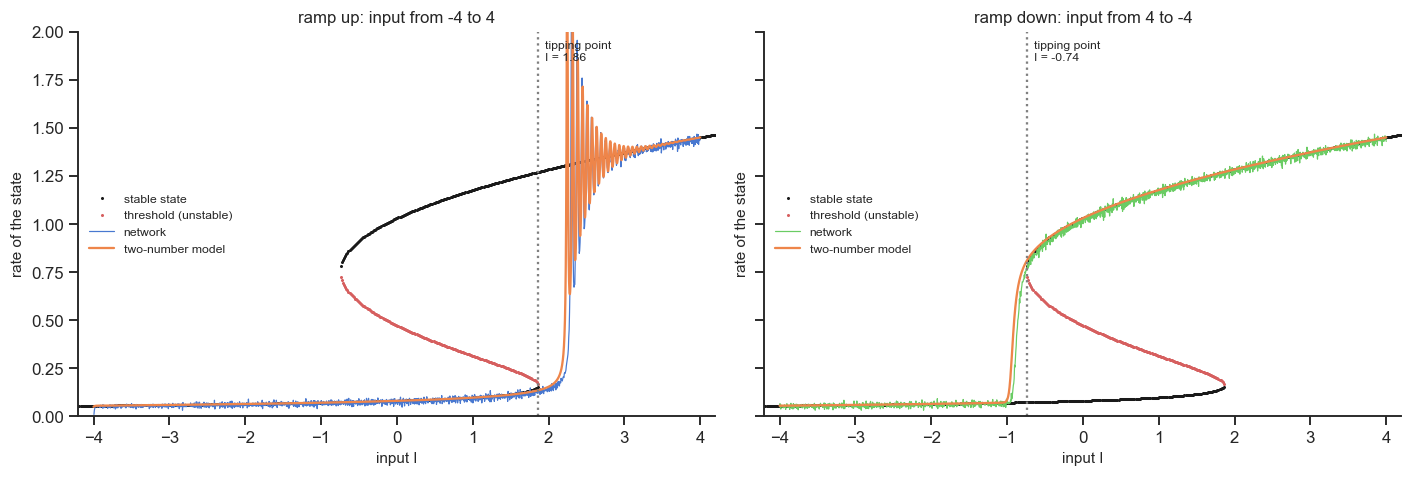

In [9]:
dt2 = 5e-4; T_ramp = 150.0
t2 = np.arange(0, 2 * T_ramp, dt2)
I_ramp = np.where(t2 < T_ramp, -4 + 8 * t2 / T_ramp, 4 - 8 * (t2 - T_ramp) / T_ramp)   # up, then down
tb2, r_net2, *_ = networks.qif_network(I_ramp, N=5000, dt=dt2, bin_size=0.1, seed=0)
r_mf2, _ = meanfield.mpr(I_ramp, dt=dt2, r0=0.05, v0=-3.0)
I_net = np.interp(tb2, t2, I_ramp)                    # input at each time bin of the network

br = meanfield.mpr_branches(np.linspace(-4, 4, 801), -5.0, 15.0)
I_bi = np.array([x[0] for x in br if not x[3]])
I_down, I_up = I_bi.min(), I_bi.max()                 # the two tipping points

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a_, (name, net_part, mf_part, c, tip) in zip(ax, [
        ("ramp up: input from -4 to 4", tb2 < T_ramp, t2 < T_ramp, "C0", I_up),
        ("ramp down: input from 4 to -4", tb2 >= T_ramp, t2 >= T_ramp, "C2", I_down)]):
    bif_diagram(a_, -5.0, 15.0, 1.0, I_range=(-4.2, 4.2))
    a_.plot(I_net[net_part], r_net2[net_part], c, lw=0.8, label="network")
    a_.plot(I_ramp[mf_part], r_mf2[mf_part], "C1", lw=1.5, label="two-number model")
    a_.axvline(tip, c="0.5", ls=":")
    a_.text(tip + 0.1, 1.85, f"tipping point\nI = {tip:.2f}", fontsize=8)
    a_.set_title(name); a_.legend(fontsize=8, loc="center left")
    #a_.set_xlim((2,3))
plt.tight_layout()
print(f"bistable for {I_down:.2f} < I < {I_up:.2f}")

* **Going up (left).** The population follows the lower black curve. Inside the bistable range it *could* be high,
  but nothing pushes it over the threshold (red), so it stays low. At $I\approx1.9$ the low state and the threshold
  meet and disappear: the population has nowhere to stay and jumps up to the high state, ringing (the damped
  oscillation) before it settles. (The jump comes a little after the tipping point because the input keeps moving
  while the population is still on its way.)
* **Coming down (right).** Now the population starts high and follows the upper black curve, all the way back
  through the bistable range, where before it was low. Only at $I\approx-0.7$, where the high state disappears,
  does it fall to the low state. For inputs in between, the activity depends on the **history**: the population remembers whether
it was switched on. This loop is called **hysteresis**, and it is a simple form of memory (think of persistent
activity in working memory, or up and down states in sleep).

It also explains the bursts under the sine input in section 2: the input sweeps back and forth across the
bistable range, and the population jumps up and down at the two tipping points.

## 5. The map of regimes (MPR Fig. 1)

Every pair (average excitability $\bar\eta$, coupling $J$) is a different population. The map shows, for each
pair, what the population can do: only low activity, only high activity, or both (bistable). It was computed
from the two-number model, which would be impossible to do neuron by neuron.

tip of the bistable region (cusp): eta_bar/Delta = -1.73, J/sqrt(Delta) = 7.80


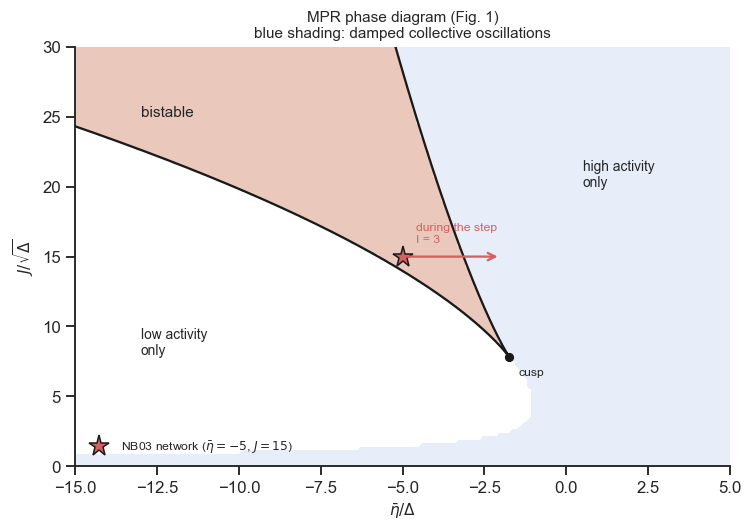

In [10]:
eta_grid = np.linspace(-15, 5, 161); J_grid = np.linspace(0, 30, 121)
n_fp = np.zeros((J_grid.size, eta_grid.size)); focus = np.zeros_like(n_fp)
for i, Jg in enumerate(J_grid):
    for k, eg in enumerate(eta_grid):
        fps = meanfield.mpr_fixed_points(eg, Jg)
        n_fp[i, k] = len(fps)
        focus[i, k] = any(classify(rs, vs, Jg)[2] == "stable focus" for rs, vs in fps)

def phase_diagram(ax):
    ax.contourf(eta_grid, J_grid, focus, levels=[0.5, 1.5], colors=["C0"], alpha=0.12)
    ax.contourf(eta_grid, J_grid, n_fp, levels=[2.5, 3.5], colors=["C1"], alpha=0.35)
    e_sn, J_sn = meanfield.mpr_saddle_node_curve(1.0)
    ax.plot(e_sn, J_sn, "k", lw=1.5)
    ax.text(-13, 25, "bistable", fontsize=10); ax.text(-13, 8, "low activity\nonly", fontsize=9)
    ax.text(0.5, 20, "high activity\nonly", fontsize=9, ha="left")
    ax.set(xlim=(-15, 5), ylim=(0, 30), xlabel=r"$\bar\eta/\Delta$", ylabel=r"$J/\sqrt{\Delta}$")

fig, ax = plt.subplots(figsize=(7, 5))
phase_diagram(ax)
ax.plot(-5, 15, "*", ms=14, c="C3", mec="k", label=r"NB03 network ($\bar\eta=-5$, $J=15$)")
ax.annotate("", xy=(-2, 15), xytext=(-5, 15), arrowprops=dict(arrowstyle="->", color="C3", lw=1.5))
ax.text(-4.6, 16, "during the step\nI = 3", fontsize=8, color="C3")
e_sn, J_sn = meanfield.mpr_saddle_node_curve(1.0); i = np.argmin(J_sn)
ax.plot(e_sn[i], J_sn[i], "ko", ms=5); ax.annotate("cusp", (e_sn[i], J_sn[i]), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.legend(fontsize=8, loc="lower left"); ax.set_title("MPR phase diagram (Fig. 1)\nblue shading: damped collective oscillations", fontsize=10)
plt.tight_layout()
print(f"tip of the bistable region (cusp): eta_bar/Delta = {e_sn[i]:.2f}, J/sqrt(Delta) = {J_sn[i]:.2f}")

* An input $I$ acts like a change of excitability: **a step of input moves the population horizontally** on the
  map (red arrow). The step $I=3$ moves our network from the bistable region into the high-activity region;
  removing it brings it back into the bistable region, where it stays high: the memory.
* The bistable region ends in a tip (the **cusp**). With weak coupling there is no bistability: recurrent
  excitation is too weak compared to how different the neurons are.
* In most of the active region the collective oscillations are **damped**: they ring and die out. A population
  that oscillates by itself needs more ingredients (delays, inhibition), or a different kind of unit: we meet one in
  NB06.

### Explore: pick a point in the phase diagram, compare network and mean field

The network has $N=5000$ neurons and a coarser time step (< 1 s per run). The step $I_0$ is applied for
$0<t<30$.

* Put the network below the cusp (e.g. $J=5$). Is there still memory after the step?
* Find a step $I_0$ that is too small to switch the network up. Where is the arrow in the phase diagram?
* Increase $\Delta$: the point moves in the rescaled diagram. Watch the oscillations and the memory.
* Where does the mean field disagree most with the network? (Try small $\Delta$.)

In [11]:
@interact(J=slider(15.0, 0.0, 25.0, 0.5, "coupling J"),
          eta_bar=slider(-5.0, -10.0, 2.0, 0.25, "mean excitability eta_bar"),
          delta=slider(1.0, 0.2, 3.0, 0.1, "heterogeneity Delta"),
          I0=slider(3.0, -3.0, 6.0, 0.25, "step amplitude I0"))
def explore_network_vs_mf(J, eta_bar, delta, I0):
    dtx = 5e-4
    tx = np.arange(T0, T, dtx)
    Ix = np.where((tx >= 0) & (tx < 30), I0, 0.0)
    tb, r_n, v_n, *_ = networks.qif_network(Ix, N=5000, J=J, eta_bar=eta_bar, delta=delta, dt=dtx, bin_size=0.05, seed=0)
    fps = meanfield.mpr_fixed_points(eta_bar, J, delta)
    r_m, v_m = meanfield.mpr(Ix, dt=dtx, r0=fps[0, 0], v0=fps[0, 1], delta=delta, eta_bar=eta_bar, J=J)
    fig = plt.figure(figsize=(13, 4.6))
    a0 = fig.add_axes([0.05, 0.13, 0.27, 0.78]); a1 = fig.add_axes([0.40, 0.55, 0.57, 0.38]); a2 = fig.add_axes([0.40, 0.13, 0.57, 0.38], sharex=a1)
    phase_diagram(a0)
    x0, y0 = eta_bar / delta, J / np.sqrt(delta)
    a0.plot(x0, y0, "*", ms=14, c="C3", mec="k")
    a0.annotate("", xy=((eta_bar + I0) / delta, y0), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color="C3", lw=1.5))
    a1.plot(tb + T0, r_n, "k", lw=0.8, label="network N = 5000"); a1.plot(tx, r_m, "C1", lw=1.4, label="two-number model")
    a1.set(ylabel="rate r", title=f"J={J}, eta_bar={eta_bar}, Delta={delta}, I0={I0}"); a1.legend(fontsize=8, loc="upper right")
    a2.plot(tb + T0, v_n, "k", lw=0.8); a2.plot(tx, v_m, "C1", lw=1.4)
    a2.set(ylabel="voltage v", xlabel="time ($\\tau_m$)", ylim=(min(-3, np.nanmin(v_m) - 0.5), 2))
    plt.setp(a1.get_xticklabels(), visible=False)
    plt.show()

interactive(children=(FloatSlider(value=15.0, continuous_update=False, description='coupling J', layout=Layout…

## 6. A model of an infinitely large crowd

The two-number model is exact only for an **infinitely large** population of QIF neurons whose excitabilities are
spread in a particular way. Real populations are finite. Here is the same step for networks of 200, 2000 and
20 000 neurons:

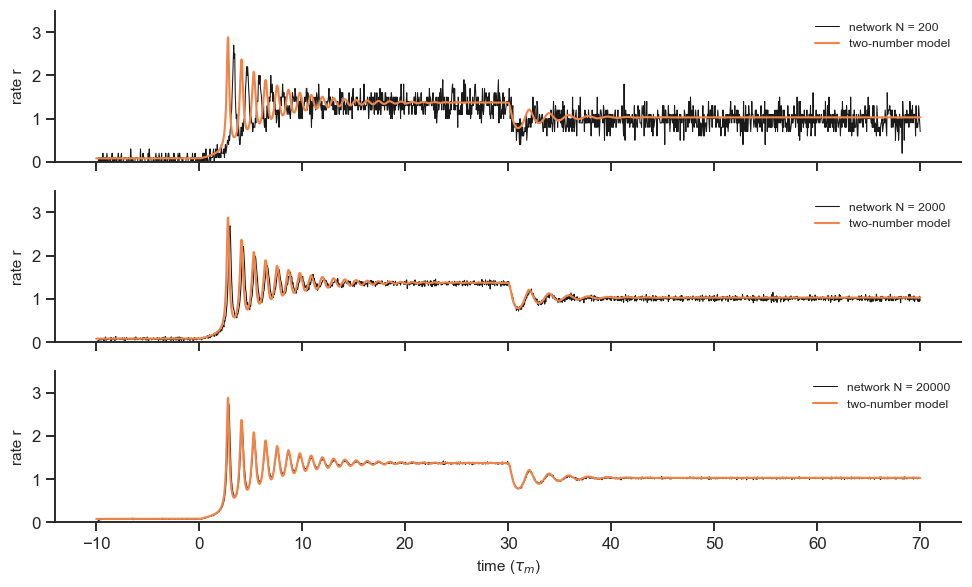

In [12]:
dt2 = 5e-4; t2 = np.arange(T0, T, dt2); I2 = np.where((t2 >= 0) & (t2 < 30), 3.0, 0.0)
r_m, _ = meanfield.mpr(I2, dt=dt2, r0=r_low, v0=v_low)
fig, ax = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True, sharey=True)
for a_, N in zip(ax, [200, 2000, 20000]):
    tb, r_n, *_ = networks.qif_network(I2, N=N, dt=dt2, bin_size=0.05, seed=1)
    a_.plot(tb + T0, r_n, "k", lw=0.7, label=f"network N = {N}"); a_.plot(t2, r_m, "C1", lw=1.4, label="two-number model")
    a_.set(ylabel="rate r", ylim=(0, 3.5)); a_.legend(fontsize=8, loc="upper right")
ax[-1].set_xlabel("time ($\\tau_m$)")
plt.tight_layout()

The bigger the network, the closer it is to the two-number model. Small networks fluctuate around it. These
fluctuations are not just noise to ignore: close to a tipping point they can switch the population between its
states on their own (Homework 3). We come back to this in Chapter 4, because this sensitivity is what makes
whole-brain models tuned near a tipping point look realistic.

## 7. Take-home

* A large population of QIF neurons is described by **two numbers**, the firing rate and the typical voltage,
  because the voltages of all neurons always take the same shape.
* The two-number model reproduces the network (MPR Fig. 2) at a tiny fraction of the cost.
* With two numbers the state of the population is a point on a map. The map shows a **low state**, a **high
  state** (reached with damped oscillations) and a **threshold** between them: **bistability**, hence memory and
  hysteresis.
* The population switches at **tipping points** (saddle-node bifurcations), the same kind as the single neuron of
  NB02: the same language describes the neuron and the population.

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. **Inhibition.** Set $J=-10$. How many fixed points are there? Is there still a damped oscillation? Compare network and
   two-number model for a step.
2. **Gaussian neurons.** Run the network with Gaussian excitabilities,
   `networks.qif_network(I, eta=np.random.default_rng(0).normal(-5, s, 10000))`, with the same half-width as the
   Lorentzian ($s = \Delta/\sqrt{2\ln 2}$). Compare with the two-number model. What changes?
3. **Noise-driven switching.** With $N=200$, $\bar\eta=-5$, $J=15$, choose a constant input inside the bistable
   range but close to the upper saddle-node (e.g. $I=1.7$). Run for a long time. Does the small network switch
   to the high state without any step? Repeat with $N=5000$.
4. **Pulse threshold.** Starting from the low state at $I=0$, apply short pulses ($\Delta t = 1$) of increasing
   amplitude. Find the smallest pulse that switches the population to high activity, in the mean field and in the
   network. Relate it to the threshold point on the map of section 3.

### References
* Montbrió E, Pazó D, Roxin A (2015). Macroscopic description for networks of spiking neurons. *Phys Rev X* 5:021028.
* Ott E, Antonsen TM (2008). Low dimensional behavior of large systems of globally coupled oscillators. *Chaos* 18:037113.
* Luke TB, Barreto E, So P (2013). Complete classification of the macroscopic behavior of a heterogeneous network of theta neurons. *Neural Comput* 25:3207–3234.
* Devalle F, Roxin A, Montbrió E (2017). Firing rate equations require a spike synchrony mechanism to correctly describe fast oscillations in inhibitory networks. *PLoS Comput Biol* 13:e1005881.
* Coombes S, Byrne Á (2019). Next generation neural mass models. In *Nonlinear Dynamics in Computational Neuroscience*, Springer.
* Wilson HR, Cowan JD (1972). Excitatory and inhibitory interactions in localized populations of model neurons. *Biophys J* 12:1–24.